<div>
    <a href="../notebook/__1_data_understanding.ipynb" style="float: left; padding: 10px; background-color: #007bff; color: white;">Previous</a>
    <a href="../notebook/__3_data_modeling.ipynb" style="float: right; padding: 10px; background-color: #007bff; color: white"> Next </a>
</div>

## Section 2 | Data Analysis
---

In [1]:
# import required library

# data ETL
import pandas as pd
from utils import convert_categorical_variable

# data analysis
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import normaltest, kruskal, mannwhitneyu
from itertools import combinations

### Data ETL

In [2]:
# data ETL
data_raw = pd.read_csv(
    filepath_or_buffer='../data/data_cleaned.csv'
)

# data cleaning
data = convert_categorical_variable(
    categorical_variables=['cylinders', 'model_year', 'origin'],
    data=data_raw
)

# show first 5 rows of cleaned data
data.head(n=5)

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg
0,307.0,8,130.0,3504,12.0,70,1,18.0
1,350.0,8,165.0,3693,11.5,70,1,15.0
2,318.0,8,150.0,3436,11.0,70,1,18.0
3,304.0,8,150.0,3433,12.0,70,1,16.0
4,302.0,8,140.0,3449,10.5,70,1,17.0


### Univariate Analysis
---
#### Tabular Analysis

In [3]:
# generate descriptive statistics from numerical variables in the dataset
data.describe(include='number' )

,displacement,horsepower,weight,acceleration,mpg
count,392.000000,392.000000,392.000000,392.000000,392.000000
mean,194.411990,104.469388,2977.584184,15.541327,23.445918
std,104.644004,38.491160,849.402560,2.758864,7.805007
min,68.000000,46.000000,1613.000000,8.000000,9.000000
25%,105.000000,75.000000,2225.250000,13.775000,17.000000
50%,151.000000,93.500000,2803.500000,15.500000,22.750000
75%,275.750000,126.000000,3614.750000,17.025000,29.000000
max,455.000000,230.000000,5140.000000,24.800000,46.600000


**Observations:**
* The exact numerical statistics of `numerical_variables` are provided above in tabular format:
    * `count` refers to the number of non-null values for each columns (similar with `Row/Instance` values in previous `Section 1: Initial Data Audit`),
    * `mean` measures the [average](https://en.wikipedia.org/wiki/Arithmetic_mean) of the values over each columns,
    * `std` represents the [standard deviation](https://en.wikipedia.org/wiki/Standard_deviation) for each variables,
    * `min` and `max` are the minimum and maximum of the values in each columns, respectively, and
    * `25%`, `50%` and `75%` are the corresponding [percentiles](https://en.wikipedia.org/wiki/Percentile) (`50%` percentile juga bisa disebut dengan [median](https://en.wikipedia.org/wiki/Median))
* `mean` and `50%` (median) values for each variables mengindikasikan bahwa `numerical_variables` tersebut tidak ada yang [berdistribusi normal](https://en.wikipedia.org/wiki/Normal_distribution), karena karakteristik dari distribusi normal is symmetric around the $µ$ parameter, which is at the same time the mean, median, and the mode (for discrete categorical variable) of the distribution —a.k.a. the values must be equal for each of them.
* Additional inferences may be provided from visual & statistical analysis below.

In [4]:
# generate descriptive statistics from categorical variables in the dataset
data.describe(include='object')

,cylinders,model_year,origin
count,392,392,392
unique,5,13,3
top,4,73,1
freq,199,40,245


**Observations:**

* Selain `count` yang serupa pada analisis `numerical_variables` sebelumnya, fungsi `describe()` untuk `categorical_variables` menunjukkan hal-hal berikut:
    1. `unique` returns distinct values in each columns,
    2. `top` is the most common value in the variable, and
    3. `freq` represents the most common value`s frequency.
* Nilai `unique` pada kolom `model_year` sejumlah `13` yang bernilai relatif lebih besar daripada kolom lainnya mengindikasikan adanya permasalahan [kardinalitas](https://en.wikipedia.org/wiki/Cardinality_(SQL_statements)).

#### Visual Analysis

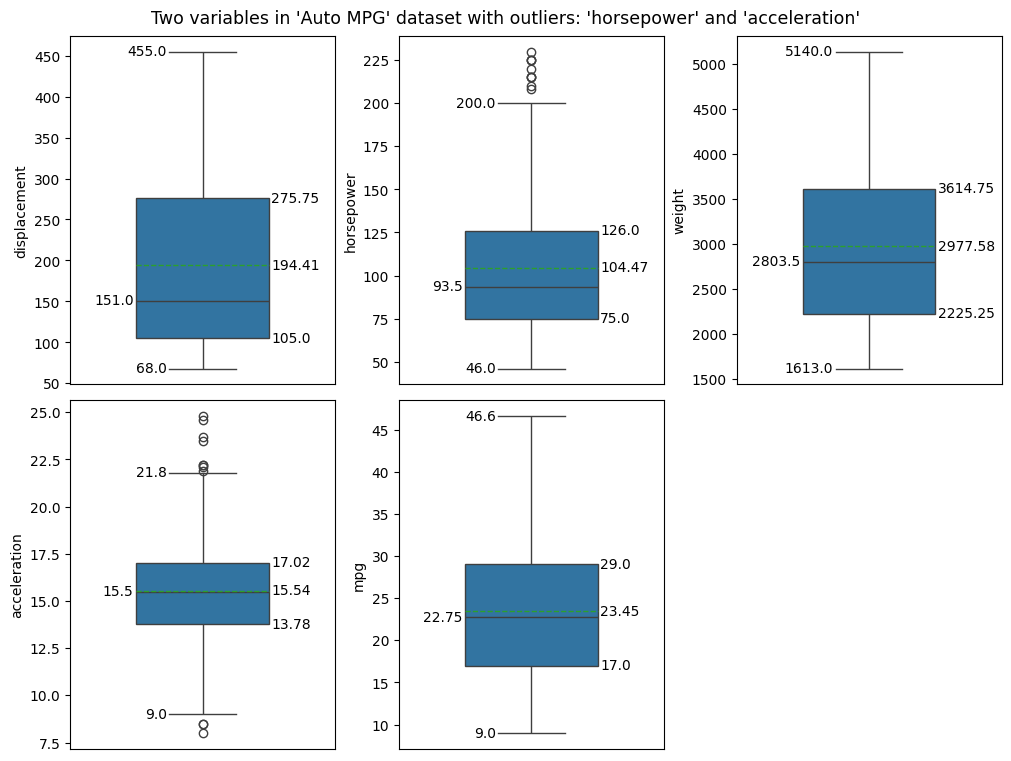

In [5]:
# subset columns with numerical data types from dataset
data_numerical = data.select_dtypes(include='number')

# create & setup plot figure
plt.figure(
    figsize=(10, 7.5),
    layout='constrained'
)
plt.suptitle(
    t="Two variables in 'Auto MPG' dataset with outliers: 'horsepower' and 'acceleration'",
    size=12.5
)
nrows = 2
ncols = 3
boxplot_width = 0.5

# create boxplot for each numerical columns
for count, column in enumerate(iterable=data_numerical):
    plt.subplot(nrows, ncols, count + 1)
    boxplot = sns.boxplot(
        data=data,
        y=column,
        width=boxplot_width,
        showmeans=True,
        meanline=True
    )
    boxplot.set_xticks(ticks=list())

    # adding boxplot elements
    x_Q1, y_Q1 = boxplot.get_lines()[0].get_xydata()[0]
    boxplot.text(x=x_Q1 + 0.26, y=y_Q1, s=round(number=y_Q1, ndigits=2), verticalalignment='center', horizontalalignment='left')

    x_Q3, y_Q3 = boxplot.get_lines()[1].get_xydata()[0]
    boxplot.text(x=x_Q3 + 0.26, y=y_Q3, s=round(number=y_Q3, ndigits=2), verticalalignment='center', horizontalalignment='left')

    x_lower_bound, y_lower_bound = boxplot.get_lines()[2].get_xydata()[0]
    boxplot.text(x=x_lower_bound - 0.01, y=y_lower_bound, s=round(y_lower_bound, 2), verticalalignment='center', horizontalalignment='right')

    x_upper_bound, y_upper_bound = boxplot.get_lines()[3].get_xydata()[0]
    boxplot.text(x=x_upper_bound - 0.01, y=y_upper_bound, s=round(y_upper_bound, 2), verticalalignment='center', horizontalalignment='right')

    x_median, y_median = boxplot.get_lines()[4].get_xydata()[0]
    boxplot.text(x=x_median - 0.01, y=y_median, s=round(number=y_median, ndigits=2), verticalalignment='center', horizontalalignment='right')

    x_mean, y_mean = boxplot.get_lines()[5].get_xydata()[0]
    boxplot.text(x=x_mean + 0.51, y=y_mean, s=round(number=y_mean, ndigits=2), verticalalignment='center', horizontalalignment='left')

**Observations:**

[Box plot](https://en.wikipedia.org/wiki/Box_plot) is a method for demonstrating graphically the locality, spread and skewness of numerical data through their quartiles. Components of the plot are as follows:
* The box by itself illustrates the interquartile spread of the distribution.
    * Its length is determined by the $25^{th}\;(Q1)$ and $75^{th}\;(Q3)$ percentiles.
    * Untuk contoh kolom `displacement` di atas, `Q1` dan `Q3` masing-masing bernilai `105.0` dan `275.75`.
* The horizontal line inside the box marks the median ($50\%$) of the distribution.
    * Pada variabel `horsepower`, median dari variabel ini adalah `93.5`.
    * Sebagai tambahan, dotted lines inside the box marks the mean of the distribution.
* The whiskers are the lines extending from the box.
    * They represent the entire scatter of data points.
    * Specifically the points that fall within the interval $Q1-(1.5\;x\;IQR),\;Q3+(1.5\;x\;IQR)$, where $IQR=Q3-Q1$ as the interquartile range.
* **Outliers** that fall outside of the range bounded by the whiskers are plotted individually as black points along the central axis.
    * Pada contoh `acceleration`, data di atas nilai `21.8` merupakan outlier pada variabel ini.
    * Dan tampak bahwa dua variabel `horsepower` dan `acceleration` yang memiliki outlier dari keseluruhan variabel numerik dalam dataset.

<center>

| Anomaly | Insight | Action |
| --- | --- | --- |
| Variable Magnitude | Variable magnitude issue detected | Analyzed further in `Section 3: Data Preprocessing` |
| **Outlier** | **Outlier issue detected** | **Analyzed further in `Section 3: Data Preprocessing`** |

</center>

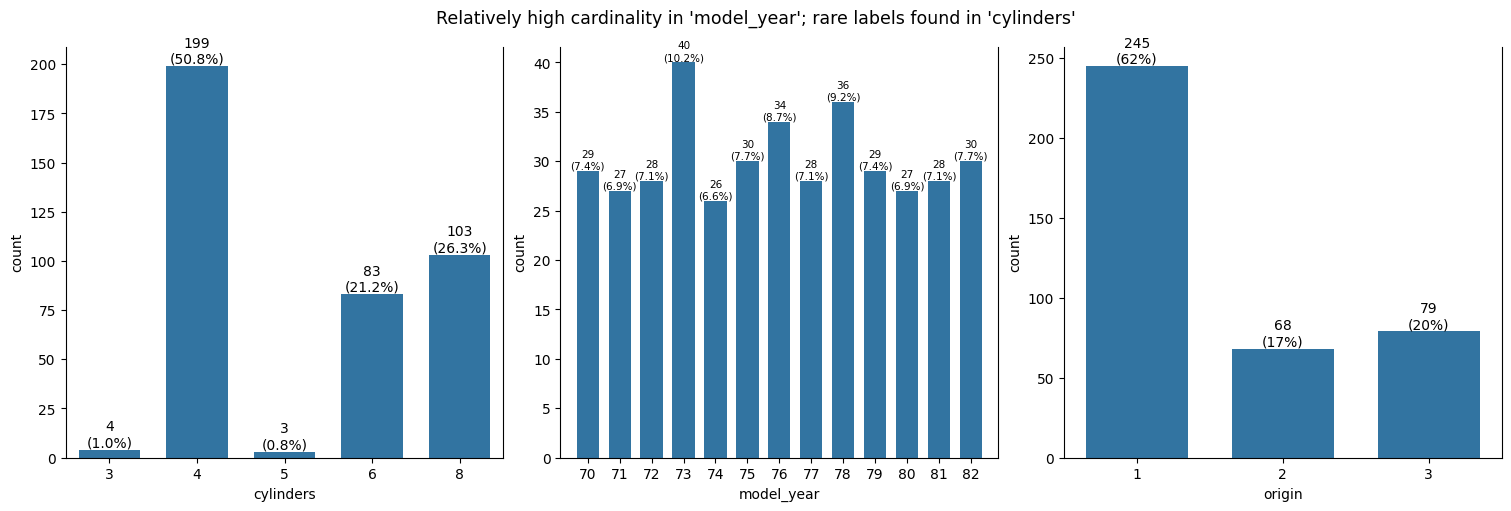

In [6]:
# subset columns with categorical data types from dataset
data_categorical = data.select_dtypes(include='object')

# create & setup plot figure
plt.figure(
    figsize=(15, 5),
    layout='constrained'
)
plt.suptitle(
    t="Relatively high cardinality in 'model_year'; rare labels found in 'cylinders'",
    size=12.5
)
nrows = 1
ncols = 3

def plot_univariate_categorical(data=data_categorical, ndigits=None, fontsize=10):
    """Function to plot univariate categorical variables using customized arguments.

    Args:
        data (DataFrame, optional): dataset for plotting. Defaults to data_categorical.
        ndigits (int or NoneType, optional): decimal digits for precision in plotting labels. Defaults to None.
        fontsize (int, optional): label font sizes. Defaults to 10.

    Returns:
        axes: Matplotlib Axes object which encapsulates all the elements of an individual (sub-)plot in a figure.
    """
    plt.subplot(nrows, ncols, count + 1)

    barplot_data = pd.concat(
        objs=[data[column].value_counts().sort_index(),
              data[column].value_counts(normalize=True).mul(other=100)],
        axis=1
    )

    axes = sns.barplot(
        data=barplot_data, 
        x=barplot_data.index,
        y="count",
        width=0.7
    )

    labels = [f"{round(value.get_height())}\n({round(number=barplot_data.iloc[index, 1], ndigits=ndigits)}%)"
              for index, value in enumerate(axes.containers[0])]
    
    axes.bar_label(
        container=axes.containers[0], 
        labels=labels,
        fontsize=fontsize
    )
    axes.spines.top.set_visible(b=False)

    return axes

# create bar plot for each categorical variables
for count, column in enumerate(iterable=data_categorical):
    if column == 'cylinders':
        plot_univariate_categorical(ndigits=1)

    elif column == 'model_year':
        axes = plot_univariate_categorical(
            ndigits=1,
            fontsize=7.5
        )
        axes.margins(0.04)
        
    else:
        plot_univariate_categorical()

**Observations:**

A [bar chart](https://en.wikipedia.org/wiki/Bar_chart) or bar graph is a chart or graph that presents categorical data with rectangular bars with heights or lengths proportional to the values that they represent.
* The graph shows comparisons among discrete categories.
    * For these particular graphs, one axis of the chart shows the specific categories being compared, and the other axis represents a measured value.
    * Categorical variables are those which values are selected from a group of categories —also called labels.
    * Tiap grafik dalam plot di atas merepresentasikan labels yang berada dalam variabel tertentu dan occurences (count) dari label tersebut.
    * Ambil contoh pada variabel `origin`, labels dengan occurences tertinggi adalah `1` sejumlah `245` observations atau `62%` dari keseluruhan dataset.

* Different categorical variables contain different number of labels or categories.
    * The variable `origin` contains only 3 labels, but `model_year`contains a relatively huge `13` different labels.
    * The number of different labels within a categorical variable is known as cardinality. A high number of labels within a variable is known as **high cardinality**.

* Different labels also appear in the dataset with different frequencies.
    * Some categories appear a lot in the dataset, whereas some other categories appear only in a few number of observations.
    * E.g. label `4` in `cylinders` appears `199` times, while the other `3` and `5` labels **rarely** appear (only `4` and `3` times, respectively).

<center>

| Anomaly | Insight | Action |
| --- | --- | --- |
| Variable Magnitude | Variable magnitude issue detected | Analyzed further in `Section 3: Data Preprocessing` |
| Outlier | Outlier issue detected | Analyzed further in `Section 3: Data Preprocessing` |
| **Cardinality** | **Cardinality issue detected** | **Analyzed further in `Section 3: Data Preprocessing`** |
| **Rare Label** | **Rare label issue detected** | **Analyzed further in `Section 3: Data Preprocessing`** |

</center>

#### Statistical Analysis

In [7]:
# apply statistical tests to each numerical columns in dataset
normaltest_results = list()

for column in data_numerical:
    skewness = data[column].skew()
    kurtosis = data[column].kurt()
    k2_statistic, pvalue = normaltest(a=data[column])
    decision = 'Reject H0' if pvalue <= 0.05 else 'Accept H0'
    normaltest_results.append({
        'skewness': skewness,
        'kurtosis': kurtosis,
        'k2_statistic': k2_statistic,
        'pvalue': pvalue,
        'decision': decision
    })

# test results in DataFrame format
pd.DataFrame(
    data=normaltest_results,
    index=data_numerical.columns
)

,skewness,kurtosis,k2_statistic,pvalue,decision
displacement,0.701669,-0.778317,54.995829,1.142372e-12,Reject H0
horsepower,1.087326,0.696947,60.288174,8.101947e-14,Reject H0
weight,0.519586,-0.809259,47.969138,3.833841e-11,Reject H0
acceleration,0.291587,0.444234,8.210940,1.648227e-02,Reject H0
mpg,0.457092,-0.515993,20.460736,3.605849e-05,Reject H0


**Observations:**

* Uji statistik yang digunakan berfokus pada normalitas distribusi dari tiap kolom dalam dataset.
    * Pertama-tama, disertakan hasil pengukuran unbiased, normalized [skewness](https://en.wikipedia.org/wiki/Skewness) and excess [kurtosis](https://en.wikipedia.org/wiki/Kurtosis) dari tiap kolom.
        * *Skewness with positive value indicates variable with positive distribution or right-skewed, and so otherwise for the negative value.*
        * *Kurtosis with value above 3 indicating variable with more extreme outliers than normal distribution (leptokurtic), and otherwise for below 3 (mesokurtic).*
    * Dan dari nilai tersebut, tidak ada satu kolom pun yang memiliki hasil pengukuran seperti distribusi normal: skewness dan excess kurtosis ≈ 0.
    * Sehingga dapat disimpulkan bahwa variabels dalam dataset bersifat non-normal/non-parametrik.
* Selaras dengan nilai skewness dan kurtosis yang telah dipaparkan, uji statistik berikutnya menggunakan [D'Agostino-Pearson](https://en.wikipedia.org/wiki/D%27Agostino%27s_K-squared_test) `normaltest` for gauging the compatibility of given data with the null hypothesis that the data is a realization of independent, identically distributed Gaussian random variables.
    * This particular test uses skewness and kurtosis to measure how much data deviate from normality (in both tails and asymmetry).
    * Kedua nilai tersebut diubah menjadi approximately standard normal samples $Z_1\, \&\, Z_2$, untuk kemudian dikombinasikan menjadi chi-squared menggunakan persamaan $K^2=Z_1^2+Z_2^2$
    * Also `normaltest` is more stable for large samples $(n\ge50)$.
* `normaltest` menghasilkan nilai test `statistic` yang mengukur seberapa jauh estimasi distribusi variabel dengan parameter dalam null hypothesis, dan `pvalue` untuk menginterpretasikan tes statistik tersebut. Dengan $\text{significance level}=0.05$, dan `pvalue` dari tiap uji statistik di atas berada di bawah signifikansi:
    * Maka dapat diambil keputusan untuk reject null hypothesis pada uji statistik di atas, dan
    * Assume bahwa tiap variabel **tidak berasal dari populasi dengan distribusi normal**.

<center>

| Anomaly | Insight | Action |
| --- | --- | --- |
| Variable Magnitude | Variable magnitude issue detected | Analyzed further in `Section 3: Data Preprocessing` |
| Outlier | Outlier issue detected | Analyzed further in `Section 3: Data Preprocessing` |
| **Normality** | **Normality issue detected** | **Analyzed further in `Section 3: Data Preprocessing`** |

</center>

### Multivariate Analysis
---
#### Numerical Variables

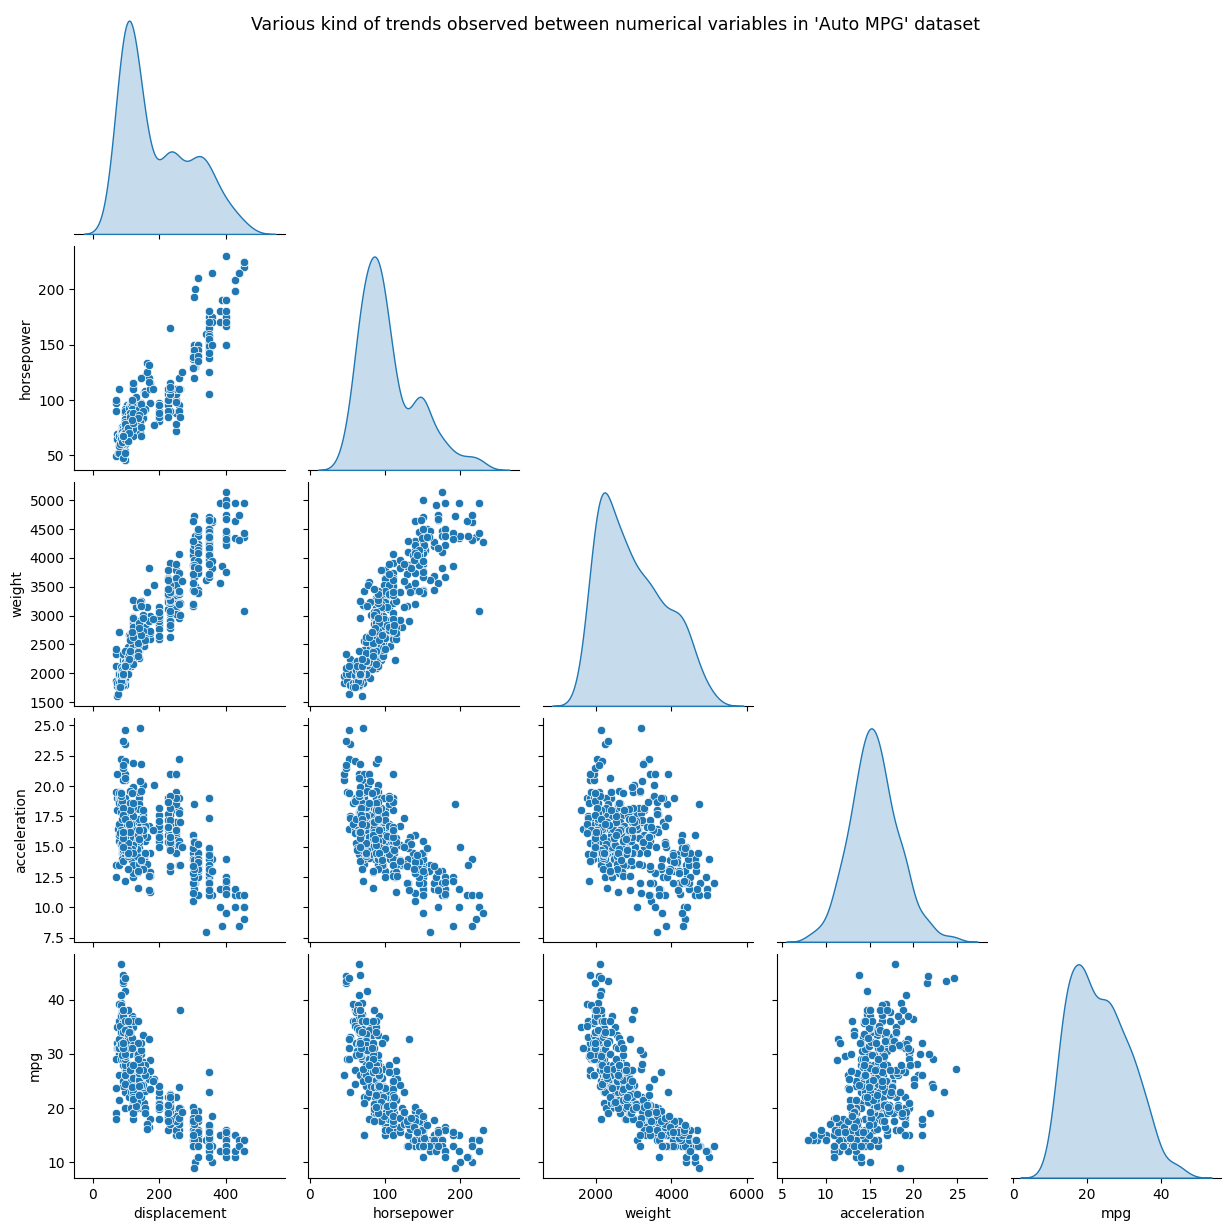

In [8]:
# plot pairwise relationship for numerical variables in dataset
sns.pairplot(
    data=data_numerical,
    corner=True,
    diag_kind='kde'
)

plt.suptitle(
    t="Various kind of trends observed between numerical variables in 'Auto MPG' dataset",
    size=12.5
)

plt.show()

**Observations:**

* Visualisasi antara variabel numerik menggunakan scatter plot dalam format pairwise relationships `pairplot`.
    * Scatter plot displays values of two numerical variables as Cartesian coordinates in 2D space. 
        * It consists of multiple data points plotted across two axes. 
        * Each variable depicted in a scatter plot would have multiple observations/points.
        * Scatter plot helps in visualizing 2 numeric variables. It helps in identifying the relationship of the data with each variable, i.e. correlation or trend patterns. 
    * Dan dalam format pairplot, scatter plots for each pair of variables fill the rest of the matrix.
        * The diagonal plots are treated differently: a univariate distribution plot (`kde` untuk menghilangkan efek dari arbitrary bins) is drawn to show the marginal distribution of the data in each column.
        * Visualisasi pairplot tidak menyertakan upper triangle `corner` karena serupa dengan lower triangle pada plot tersebut.
* Pola yang terlihat pada pairplot tersebut sebagai berikut:
    * Almost perfectly linear upward trend between `displacement`, `horsepower`, and `weight` indicates a strong positive relationships.
        * Examples of interpretation between them is heavier cars tend to have larger engines, and also larger engines produce more power.
        * These variables form a highly **collinear** cluster, since they all move together in the same direction.
    * But between aforementioned variables and `mpg`, strong downward curves are observed.
        * Heavier, more powerful cars seems to have worse fuel efficiency.
        * Concave patterns may suggest non-linear relationships, as diminishing fuel efficiency comes from increasing car power/size.
    * Mild negative relationships can be seen between `acceleration` and the collinear cluster.
        * And the opposite happens between this variable and the target: faster cars may have better miles per gallon of fuel, but the relationship is weak and noisy.
        * Another inference may be taken that there are no clear linear trends between them.

<center>

| Anomaly | Insight | Action |
| --- | --- | --- |
| Variable Magnitude | Variable magnitude issue detected | Analyzed further in `Section 3: Data Preprocessing` |
| Outlier | Outlier issue detected | Analyzed further in `Section 3: Data Preprocessing` |
| Normality | Normality issue detected | Analyzed further in `Section 3: Data Preprocessing` |
| **Collinearity** | **Collinearity issue detected** | **Analyzed further in `Section 3: Data Preprocessing`** |

</center>

#### Categorical Variables

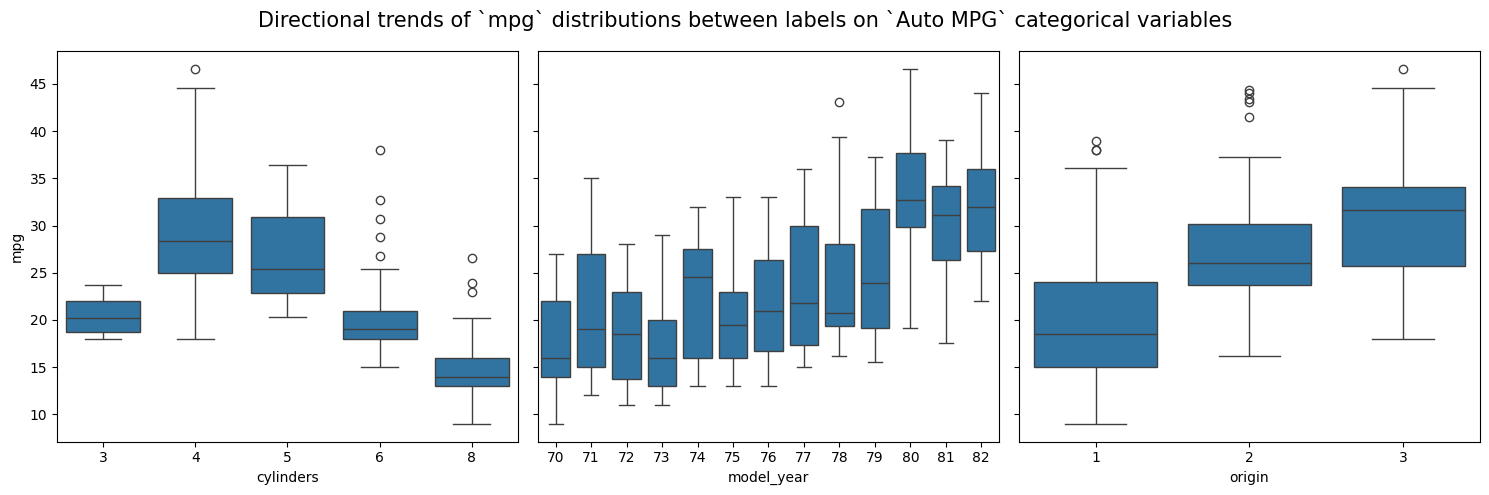

In [9]:
# plot pairwise relationship for categorical features and target variable in dataset
_, axes = plt.subplots(
    nrows=1,
    ncols=3,
    sharey=True,
    figsize=(15, 5),
    layout='tight'
)

plt.suptitle(
    t="Directional trends of `mpg` distributions between labels on `Auto MPG` categorical variables",
    size=15
)

for count, column in enumerate(iterable=data_categorical):
    # column_labels = data[column].unique()
    # column_grouped = [data[data[column] == label]['mpg'] for label in column_labels]
    # h_statistic, pvalue = kruskal(*column_grouped)

    sns.boxplot(
        data=data,
        x=column,
        y='mpg',
        ax=axes[count]
    )\
    # .set_title(
    #     label=f'H = {h_statistic:.2e}, p = {pvalue:.2e}'
    # )

plt.show()

**Observations:**

* Untuk variabel kategorikal, visualisasi yang diterapkan berfokus pada hubungan antara variabel (feature) tersebut dengan target variable `mpg`.
    * Visualisasi menggunakan `boxplot` sesuai dengan yang telah diterapkan pada `Section 2: Visual Analysis` sebelumnya
    * Dapat dilihat distribusi label pada tiap variabel kategorikal berdasarkan nilai dari `mpg`, yang juga berperan untuk memberikan insight terhadap asosiasi antara pasangan variabel tersebut.
* Interpretasi hubungan antar variabel dalam boxplot di atas adalah sebagai berikut:
    * **Seiring bertambahnya `cylinders`, nilai `mpg` turut menurun.**
        * Mobil dengan `cylinders: 4` memiliki nilai `mpg` yang paling besar, baik secara rerata maupun jangkauan persebarannya. Dapat dimaknai bahwa mobil-mobil ini adalah kendaraan paling fuel-efficient.
        * Tren yang sama tidak didapatkan dari `cylinders: 3`. Salah satu kemungkinan penyebabnya adalah jumlah data pada label ini yang jauh lebih sedikit daripada label lainnya sesuai dengan yang telah ditunjukkan pada `Section 2: Visual Analysis`.
    * **Sedangkan nilai `mpg` meningkat dengan bertambahnya `model_year` dan `origin`.**
        * Nilai tengah `mpg` untuk kendaraan dengan `model_year` from the 70s berkisar antara `15-25`, while the 80s meningkat around `30`.
        * Untuk mobil dengan `origin: 1` atau berasal dari U.S., they generally have lower `mpg`, while the opposite happens from `origin: 3` or Japan cars.

<div>
    <a href="../notebook/__1_business_and_data_understanding.ipynb" style="float: left; padding: 10px; background-color: #007bff; color: white;">Previous</a>
    <a href="../notebook/__3_data_modeling.ipynb" style="float: right; padding: 10px; background-color: #007bff; color: white"> Next </a>
</div>